### Case 6.1

In [19]:
import jieba
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

messages_300 = r"C:\Users\PC\Desktop\文本数据处理与应用实操\data\case6\messages_300.csv"
stopwords = r"C:\Users\PC\Desktop\文本数据处理与应用实操\data\case6\stopwords.txt"

df = pd.read_csv(messages_300)
stop = set(open(stopwords, encoding='utf-8').read().split())

# 步骤1：清洗、分词、去停用词，生成 TF-IDF
df['seg'] = df['content'].apply(
    lambda s: ' '.join(w for w in jieba.lcut(s) if len(w) > 1 and w not in stop))
tv = TfidfVectorizer(max_df=0.8, min_df=2, token_pattern=r'(?u)\S+')
X = tv.fit_transform(df['seg'])

In [20]:
# 步骤2：K-Means 聚类
km = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X)
df['cluster'] = km.labels_

In [21]:
# 步骤3：每簇条数 + 簇中心权重最高的 10 个词
print(df['cluster'].value_counts().sort_index())
terms = tv.get_feature_names_out()
order = km.cluster_centers_.argsort()[:, ::-1]
for k in range(5):
    print('簇', k, [terms[i] for i in order[k, :10]])

cluster
0    59
1    54
2    53
3    73
4    61
Name: count, dtype: int64
簇 0 ['医院', '方便', '就医', '看病', '老人', '药品', '医保', '齐全', '挂号', '时间']
簇 1 ['小区', '物业', '问题', '房屋', '多次', '公共设施', '反映', '居民', '处理', '开发商']
簇 2 ['通行', '地铁', '道路交通', '衔接', '越来越', '车辆', '出行', '公交', '安全', '效率']
簇 3 ['垃圾', '噪音', '了解', '问题', '水质', '居民', '环境污染问题', '身体健康', '空气', '环保部门']
簇 4 ['孩子', '学校', '老师', '上学', '家长', '教育部门', '意见', '领导', '学生', '入园']


In [22]:
# 步骤4：根据高频词人工命名
names = {0: '医疗类', 1: '住房类', 2:'交通类' , 3: '环境类', 4: '教育类'} 

In [23]:
# 步骤5：用隐藏的真实类别做交叉表，并计算纯度
ct = pd.crosstab(df['cluster'], df['category'])
print(ct)
print('纯度：', ct.max(axis=1).sum() / len(df))

category  交通  住房  医疗  教育  环境
cluster                     
0          5   0  54   0   0
1          2  52   0   0   0
2         49   0   0   0   4
3          2   7   5   4  55
4          2   1   1  56   1
纯度： 0.8866666666666667


### Case 6.2

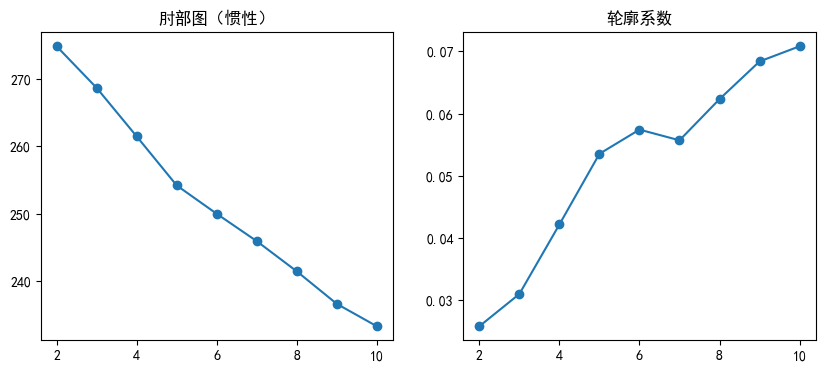

In [24]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams['font.sans-serif'] = ['SimHei']
# X、tv、df 沿用案例 6.1

# 步骤1、2：K=2…10，记录惯性和轮廓系数
ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, 'o-')
ax[0].set_title('肘部图（惯性）')
ax[1].plot(ks, sil, 'o-')
ax[1].set_title('轮廓系数')
plt.savefig('choose_k.png', dpi=150)

In [25]:
# 步骤3：对比 K=3/5/8 的簇关键词
terms = tv.get_feature_names_out()
for k in (3, 5, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    order = km.cluster_centers_.argsort()[:, ::-1]
    print('K =', k)
    for c in range(k):
        print('  簇', c, [terms[i] for i in order[c, :8]])

K = 3
  簇 0 ['小区', '问题', '物业', '反映', '房屋', '一个', '了解', '噪音']
  簇 1 ['医院', '方便', '就医', '看病', '孩子', '老人', '新增', '药品']
  簇 2 ['影响', '领导', '请问', '通行', '您好', '附近', '地铁', '居民']
K = 5
  簇 0 ['医院', '方便', '就医', '看病', '老人', '药品', '医保', '齐全']
  簇 1 ['小区', '物业', '问题', '房屋', '多次', '公共设施', '反映', '居民']
  簇 2 ['通行', '地铁', '道路交通', '衔接', '越来越', '车辆', '出行', '公交']
  簇 3 ['垃圾', '噪音', '了解', '问题', '水质', '居民', '环境污染问题', '身体健康']
  簇 4 ['孩子', '学校', '老师', '上学', '家长', '教育部门', '意见', '领导']
K = 8
  簇 0 ['小区', '物业', '问题', '房屋', '多次', '公共设施', '处理', '开发商']
  簇 1 ['家长', '学校', '学生', '意见', '居民', '听取', '应当', '请问']
  簇 2 ['通行', '效率', '越来越', '安全', '出行', '您好', '噪音', '车辆']
  簇 3 ['地铁', '道路交通', '衔接', '公交', '改善', '需要', '公交线路', '街道']
  簇 4 ['满意', '非常', '预约', '方便', '接驳', '新增', '焕然一新', '出行']
  簇 5 ['医院', '就医', '看病', '药品', '方便', '时间', '齐全', '老人']
  簇 6 ['水质', '问题', '环保部门', '环境', '垃圾', '河道', '担忧', '巡查']
  簇 7 ['孩子', '老师', '感谢', '教学', '耐心', '上学', '服务', '课后']


### Case 6.3  LDA主题模型

In [26]:
import jieba
import pandas as pd
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

messages_300 = r"C:\Users\PC\Desktop\文本数据处理与应用实操\data\case6\messages_300.csv"
stopwords = r"C:\Users\PC\Desktop\文本数据处理与应用实操\data\case6\stopwords.txt"

df = pd.read_csv(messages_300)
stop = set(open(stopwords, encoding='utf-8').read().split())

# 步骤1：分词、建词典、过滤极端词频
texts = [[w for w in jieba.lcut(s) if len(w) > 1 and w not in stop] for s in df['content']]
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=3, no_above=0.5)

In [27]:
# 步骤2：生成词袋语料，训练 LDA
bow = [dictionary.doc2bow(t) for t in texts]
lda = LdaModel(bow, num_topics=5, id2word=dictionary, passes=10, random_state=42)

In [28]:
# 步骤3：输出每个主题的 Top10 词，人工命名
for tid, words in lda.show_topics(num_topics=5, num_words=10, formatted=False):
    print('主题', tid, [w for w, _ in words])

主题 0 ['改善', '领导', '您好', '公交', '请问', '噪音', '感谢', '环保部门', '环境', '地铁']
主题 1 ['希望', '居民', '就医', '方便', '医院', '看病', '领导', '老人', '药品', '时间']
主题 2 ['小区', '领导', '孩子', '您好', '需要', '请问', '了解', '学校', '加强', '感谢']
主题 3 ['问题', '小区', '反映', '一个', '影响', '多次', '很大', '居民', '物业', '房屋']
主题 4 ['学校', '意见', '领导', '时间', '家长', '解决', '影响', '问题', '没有', '教育部门']


In [29]:
# 步骤4：主题数 3/5/8 对比，用一致性 c_v 选择，一致性 c_v 是用来衡量 LDA 模型生成的主题是否具有语义连贯性的指标
for n in (3, 5, 8):
    m = LdaModel(bow, num_topics=n, id2word=dictionary, passes=10, random_state=42)
    cm = CoherenceModel(model=m, texts=texts, dictionary=dictionary, coherence='c_v')
    print('主题数', n, '一致性', round(cm.get_coherence(), 3))

主题数 3 一致性 0.27
主题数 5 一致性 0.366
主题数 8 一致性 0.296
